<a href="https://colab.research.google.com/github/Xquisite-design/enterprise-presales-knowledge-orchestration/blob/main/notebooks/03_RQ1_Enterprise_Knowledge_Requirement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 3 of 5 : RQ1 - Enterprise Knowledge Requirement

Inferential statistics, feature engineering, baseline and tuned models, evaluation and explainability for RQ1.

**Run first:** `01_Data_Loading_Quality_Cleaning.ipynb` &nbsp;|&nbsp; **Next:** `04_RQ2_Knowledge_Routing_Agent.ipynb`

In [ ]:
###############################################################
# SETUP : MOUNT DRIVE, IMPORTS AND LOAD HANDOFF DATA
###############################################################

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = "/content/drive/MyDrive/DataAnalytics_Capstone"
HANDOFF_DIR = f"{BASE_DIR}/handoff"

# Cleaned dataset saved by 01_Data_Loading_Quality_Cleaning.ipynb
df = pd.read_pickle(f"{HANDOFF_DIR}/cleaned_dataset.pkl")

print(df.shape)

#PART-B: RQ1

## 1. Inferential Statistics (RQ1 specific)

Objective: This section explores the relationship between the characteristics of enterprise presales questions and whether they can be answered using publicly available knowledge alone or require additional enterprise knowledge.

The analysis serves two purposes:

- To understand the characteristics of the curated corpus.
- To identify variables that may be useful predictors for the Binary Logistic Regression model.

In [8]:
# Store statistical results for summary table
summary_results = []

In [9]:
###############################################################
# RQ EXPLORATORY ANALYSIS FUNCTION
#
# Performs:
# 1. Frequency Table
# 2. Percentage Table
# 3. Stacked Bar Chart
# 4. Chi-square Test
# 5. Cramer's V
# 6. Statistical Interpretation
###############################################################

import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
import numpy as np

def analyze_predictor_vs_target(df, predictor, target):

    print("\n" + "="*80)
    print(f"Analyzing: {predictor} vs {target}")
    print("="*80)

    try:
        # ----------------------------------------------------------
        # Cross Tabulation
        # ----------------------------------------------------------

        contingency = pd.crosstab(df[predictor], df[target])

        print("\nContingency Table\n")
        display(contingency)

        # ----------------------------------------------------------
        # Row Percentages
        # ----------------------------------------------------------

        percentage = pd.crosstab(
            df[predictor],
            df[target],
            normalize='index'
        ) * 100

        print("\nPercentage Distribution\n")
        display(percentage.round(2))

        # ----------------------------------------------------------
        # Stacked Bar Chart
        # ----------------------------------------------------------

        ax = percentage.plot(
            kind='bar',
            stacked=True,
            figsize=(10,6)
        )

        plt.title(f"{predictor} vs {target}")

        plt.ylabel("Percentage")

        plt.xlabel(predictor)

        plt.xticks(rotation=30)

        plt.legend(title=target)

        plt.tight_layout()

        plt.show()

        # ----------------------------------------------------------
        # Chi-square Test
        # ----------------------------------------------------------

        chi2, p, dof, expected = chi2_contingency(contingency)

        print("\n")
        print("="*60)
        print("Chi-square Test")
        print("="*60)

        print(f"Chi-square Statistic : {chi2:.3f}")

        print(f"Degrees of Freedom   : {dof}")

        print(f"P-value              : {p:.5f}")

        # ----------------------------------------------------------
        # Cramer's V
        # ----------------------------------------------------------

        n = contingency.sum().sum()

        # Ensure min_dim is not zero to prevent ZeroDivisionError
        min_dim = min(contingency.shape) - 1
        if min_dim == 0:
            cramers_v = np.nan # Or handle as appropriate, e.g., 0 or skip
            print("Cramer's V: Cannot be calculated (min_dim is 0).")
        else:
            cramers_v = np.sqrt(chi2/(n*min_dim))
            print(f"Cramer's V           : {cramers_v:.3f}")

        # ----------------------------------------------------------
        # Interpretation
        # ----------------------------------------------------------

        print("\n")
        print("="*60)
        print("Interpretation")
        print("="*60)

        if p < 0.05:
            print("✓ Reject the Null Hypothesis")
            print("There is a statistically significant association.")

        else:
            print("✓ Fail to Reject the Null Hypothesis")
            print("No statistically significant association detected.")

        if pd.isna(cramers_v) or cramers_v < 0.10:
            strength = "Negligible"

        elif cramers_v < 0.30:
            strength = "Weak"

        elif cramers_v < 0.50:
            strength = "Moderate"

        else:
            strength = "Strong"

        print(f"Association Strength : {strength}")

        print("\nSuggested for Logistic Regression:")

        if p < 0.05:
            print("YES")

        else:
            print("Consider excluding this predictor.")

        # ----------------------------------------------------------
        # Store Results
        # ----------------------------------------------------------

        if pd.isna(cramers_v) or cramers_v < 0.10:
            effect = "Negligible"
        elif cramers_v < 0.30:
            effect = "Weak"
        elif cramers_v < 0.50:
            effect = "Moderate"
        else:
            effect = "Strong"

        summary_results.append({

            "Predictor": predictor,

            "Chi-square": round(chi2,3),

            "Degrees of Freedom": dof,

            "P-value": round(p,5),

            "Cramer's V": round(cramers_v,3) if not pd.isna(cramers_v) else cramers_v,

            "Effect Size": effect,

            "Statistically Significant":
                "Yes" if p < 0.05 else "No",

            "Include in Logistic Regression":
                "Yes" if p < 0.05 else "No"

        })
    except Exception as e:
        print(f"An error occurred while processing {predictor}: {e}")
        print("Skipping this predictor and continuing with the next ones if any.")


Analyzing: Question Type vs Public Knowledge Only?

Contingency Table



Public Knowledge Only?,Partially,Yes
Question Type,,
Architecture,255,62
Best Practice,118,17
Commercial / Pricing,150,24
Governance / Security,109,14
Implementation,42,4
Informational,45,20
Migration,35,5



Percentage Distribution



Public Knowledge Only?,Partially,Yes
Question Type,,
Architecture,80.44,19.56
Best Practice,87.41,12.59
Commercial / Pricing,86.21,13.79
Governance / Security,88.62,11.38
Implementation,91.30,8.70
Informational,69.23,30.77
Migration,87.50,12.50


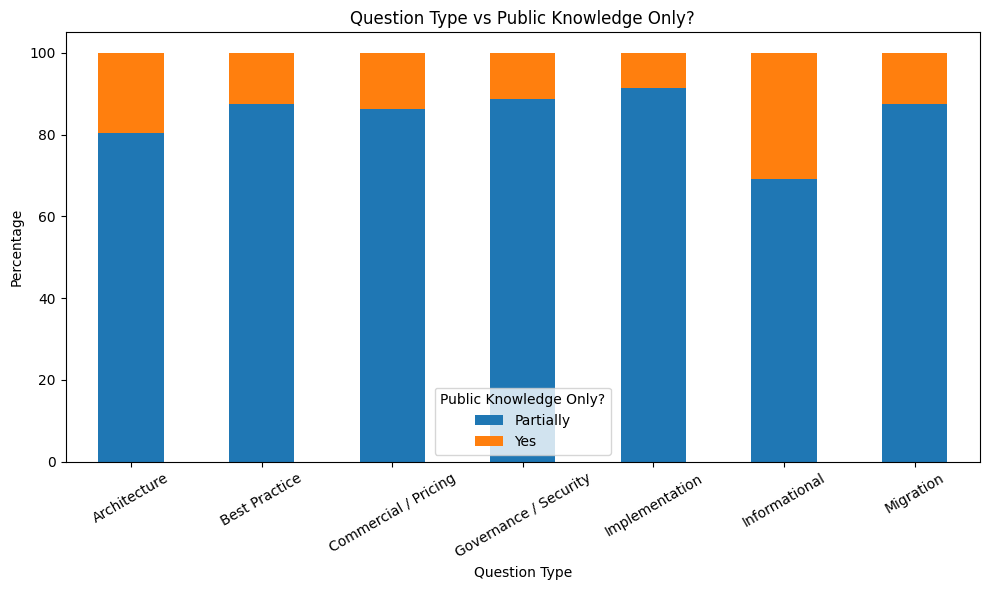



Chi-square Test
Chi-square Statistic : 19.226
Degrees of Freedom   : 6
P-value              : 0.00380
Cramer's V           : 0.146


Interpretation
✓ Reject the Null Hypothesis
There is a statistically significant association.
Association Strength : Weak

Suggested for Logistic Regression:
YES

Analyzing: Question Complexity vs Public Knowledge Only?

Contingency Table



Public Knowledge Only?,Partially,Yes
Question Complexity,,
High,590,100
Low,33,14
Medium,131,32



Percentage Distribution



Public Knowledge Only?,Partially,Yes
Question Complexity,,
High,85.51,14.49
Low,70.21,29.79
Medium,80.37,19.63


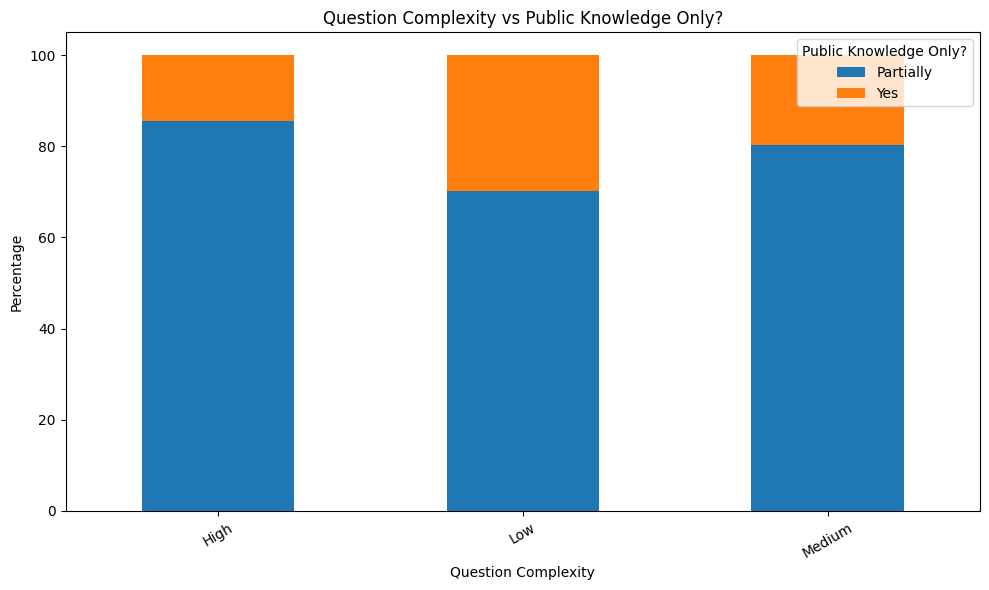



Chi-square Test
Chi-square Statistic : 9.276
Degrees of Freedom   : 2
P-value              : 0.00967
Cramer's V           : 0.102


Interpretation
✓ Reject the Null Hypothesis
There is a statistically significant association.
Association Strength : Weak

Suggested for Logistic Regression:
YES

Analyzing: Technology Domain vs Public Knowledge Only?

Contingency Table



Public Knowledge Only?,Partially,Yes
Technology Domain,,
Analytics / Data Platform,65,11
Cloud Architecture,11,5
Cost Optimization,12,1
DevOps / Platform Engineering,29,6
GenAI / AI,81,25
Migration / Modernization,37,2
Networking,167,40
Operations / Monitoring,0,3
Resilience / DR,28,2



Percentage Distribution



Public Knowledge Only?,Partially,Yes
Technology Domain,,
Analytics / Data Platform,85.53,14.47
Cloud Architecture,68.75,31.25
Cost Optimization,92.31,7.69
DevOps / Platform Engineering,82.86,17.14
GenAI / AI,76.42,23.58
Migration / Modernization,94.87,5.13
Networking,80.68,19.32
Operations / Monitoring,0.00,100.00
Resilience / DR,93.33,6.67


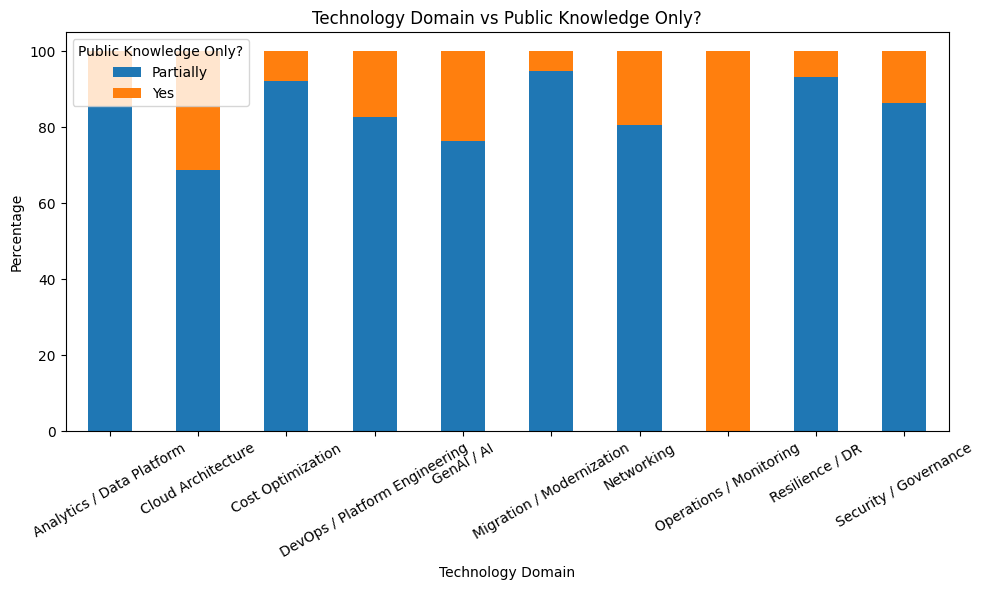



Chi-square Test
Chi-square Statistic : 32.178
Degrees of Freedom   : 9
P-value              : 0.00019
Cramer's V           : 0.189


Interpretation
✓ Reject the Null Hypothesis
There is a statistically significant association.
Association Strength : Weak

Suggested for Logistic Regression:
YES

Analyzing: Business Capability vs Public Knowledge Only?

Contingency Table



Public Knowledge Only?,Partially,Yes
Business Capability,,
AI-enabled business capability,81,25
Business continuity and resilience,28,2
Cloud foundation and workload architecture,11,5
Cloud migration and modernization,37,2
Digital platform delivery,29,6
Enterprise data and analytics,65,11
Financial governance / FinOps,12,1
Hybrid connectivity and network foundation,167,40
IT operations and observability,0,3



Percentage Distribution



Public Knowledge Only?,Partially,Yes
Business Capability,,
AI-enabled business capability,76.42,23.58
Business continuity and resilience,93.33,6.67
Cloud foundation and workload architecture,68.75,31.25
Cloud migration and modernization,94.87,5.13
Digital platform delivery,82.86,17.14
Enterprise data and analytics,85.53,14.47
Financial governance / FinOps,92.31,7.69
Hybrid connectivity and network foundation,80.68,19.32
IT operations and observability,0.00,100.00


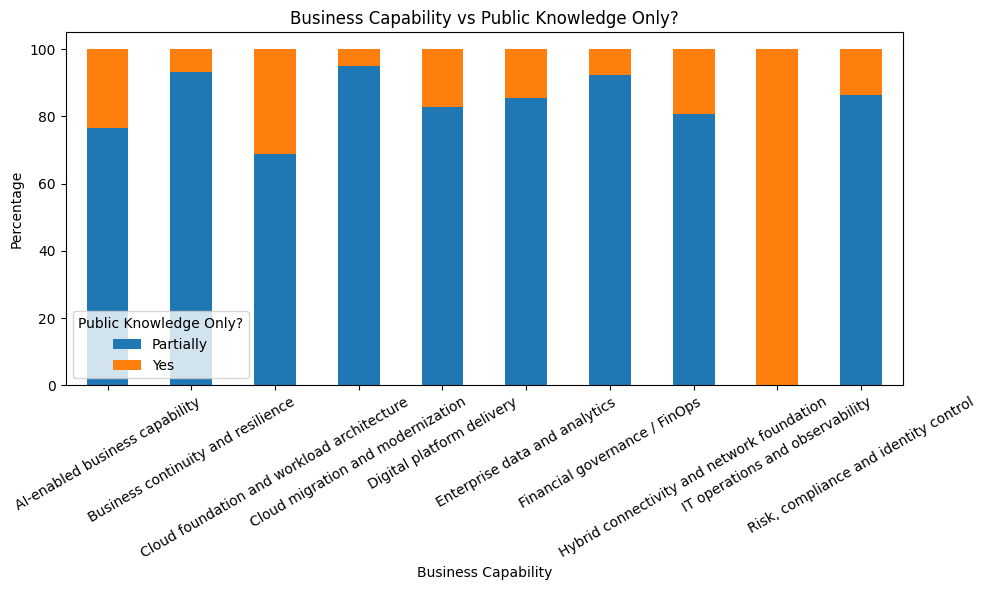



Chi-square Test
Chi-square Statistic : 32.178
Degrees of Freedom   : 9
P-value              : 0.00019
Cramer's V           : 0.189


Interpretation
✓ Reject the Null Hypothesis
There is a statistically significant association.
Association Strength : Weak

Suggested for Logistic Regression:
YES

Analyzing: Question Intent vs Public Knowledge Only?

Contingency Table



Public Knowledge Only?,Partially,Yes
Question Intent,,
Assess business rationale,30,0
Determine implementation approach,208,12
Determine timing / applicability,26,0
Estimate commercial impact,35,1
Evaluate options / fit,35,4
Request presales guidance,310,54
Understand capability / terminology,110,75



Percentage Distribution



Public Knowledge Only?,Partially,Yes
Question Intent,,
Assess business rationale,100.00,0.00
Determine implementation approach,94.55,5.45
Determine timing / applicability,100.00,0.00
Estimate commercial impact,97.22,2.78
Evaluate options / fit,89.74,10.26
Request presales guidance,85.16,14.84
Understand capability / terminology,59.46,40.54


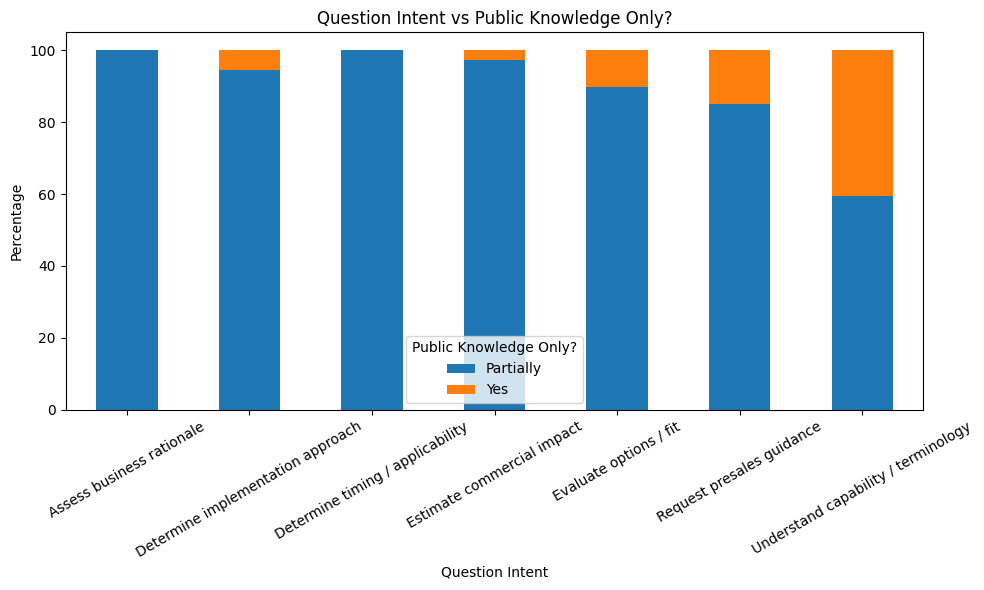



Chi-square Test
Chi-square Statistic : 116.437
Degrees of Freedom   : 6
P-value              : 0.00000
Cramer's V           : 0.360


Interpretation
✓ Reject the Null Hypothesis
There is a statistically significant association.
Association Strength : Moderate

Suggested for Logistic Regression:
YES


In [10]:
# RQ1 Predictor Analysis

target = "Public Knowledge Only?"

predictors = [

    "Question Type",

    "Question Complexity",

    "Technology Domain",

    "Business Capability",

    "Question Intent"

]

for predictor in predictors:

    analyze_predictor_vs_target(df, predictor, target)

In [11]:
###############################################################
# SUMMARY OF ALL PREDICTOR ANALYSES
###############################################################

summary_df = pd.DataFrame(summary_results)

summary_df = summary_df.sort_values(
    by="Cramer's V",
    ascending=False
)

print("="*90)
print("SUMMARY OF EXPLORATORY INFERENTIAL ANALYSIS")
print("="*90)

display(summary_df)

SUMMARY OF EXPLORATORY INFERENTIAL ANALYSIS


,Predictor,Chi-square,Degrees of Freedom,P-value,Cramer's V,Effect Size,Statistically Significant,Include in Logistic Regression
4,Question Intent,116.437,6,0.00000,0.360,Moderate,Yes,Yes
3,Business Capability,32.178,9,0.00019,0.189,Weak,Yes,Yes
2,Technology Domain,32.178,9,0.00019,0.189,Weak,Yes,Yes
0,Question Type,19.226,6,0.00380,0.146,Weak,Yes,Yes
1,Question Complexity,9.276,2,0.00967,0.102,Weak,Yes,Yes


An exploratory inferential analysis was conducted to examine the association between each candidate predictor and the target variable (Public Knowledge Only?) prior to model development. Chi-square tests indicated that Question Type, Question Complexity, Technology Domain, Business Capability, and Question Intent were all significantly associated with the target variable (p < 0.05). Although most relationships exhibited weak effect sizes (Cramér's V = 0.10–0.19), Question Intent demonstrated a moderate association (Cramér's V = 0.36), suggesting that the intent behind a presales question is the strongest indicator of whether enterprise knowledge is required. Consequently, all five predictors were retained for the subsequent Binary Logistic Regression analysis.

## 2. Feature Engineering

In [12]:
###############################################################
# FEATURE ENGINEERING
###############################################################

# From the above analysis, we are not using Technology Domain.

###############################################################
# Select final predictor variables
###############################################################

predictors = [

    "Question Type",

    "Question Complexity",

    "Question Intent",

    "Business Capability"

]

target = "Public Knowledge Only?"

In [13]:
#All predictors are categorical and Logistic Regression needs numbers.

###############################################################
# One-Hot Encoding
#
# Converts categorical variables into binary indicator
# variables suitable for Logistic Regression.
###############################################################

X = pd.get_dummies(

    df[predictors],

    drop_first=True

)

# Convert boolean columns to integer (0 or 1)
X = X.astype(int)

###############################################################
# Encode Target Variable
###############################################################

y = df[target].map({

    "Yes":1,

    "Partially":0

})

print(X.shape)

print(y.value_counts())

(900, 23)
Public Knowledge Only?
0    754
1    146
Name: count, dtype: int64


## 3. Baseline ML models

In [14]:
###############################################################
# Split Dataset
###############################################################

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    stratify=y

)

print("Training Records :",len(X_train))

print("Testing Records :",len(X_test))

Training Records : 720
Testing Records : 180


In [15]:
###############################################################
# BUILD BASELINE MODELS
###############################################################

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

baseline_models = {

    "Logistic Regression":
        LogisticRegression(
            random_state=42,
            max_iter=1000
        ),

    "Balanced Logistic":
        LogisticRegression(
            class_weight="balanced",
            random_state=42,
            max_iter=1000
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            random_state=42
        ),

    "XGBoost":
        XGBClassifier(
            random_state=42,
            eval_metric="logloss"
        )
}

In [16]:
import statsmodels.api as sm

X_sm = sm.add_constant(X)

logit = sm.Logit(y, X_sm)

result = logit.fit_regularized(alpha=0.01)

print(result.summary())


Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.3610868140309803
            Iterations: 523
            Function evaluations: 523
            Gradient evaluations: 523
                             Logit Regression Results                             
Dep. Variable:     Public Knowledge Only?   No. Observations:                  900
Model:                              Logit   Df Residuals:                      876
Method:                               MLE   Df Model:                           23
Date:                    Tue, 04 Aug 2026   Pseudo R-squ.:                  0.1866
Time:                            04:17:52   Log-Likelihood:                -324.53
converged:                           True   LL-Null:                       -399.00
Covariance Type:                nonrobust   LLR p-value:                 2.004e-20
                                                                     coef    std err          z      P>|z|      [0.025     

## 4. Hyperparameter Tuning

In [17]:
###############################################################
# HYPERPARAMETER TUNING
###############################################################

from sklearn.model_selection import RandomizedSearchCV

In [18]:
#Tuning Decision Tree

tree_grid = {

    "criterion":["gini","entropy"],

    "max_depth":[3,5,7,10,None],

    "min_samples_split":[2,5,10],

    "min_samples_leaf":[1,2,4]

}

tree_search = RandomizedSearchCV(

    DecisionTreeClassifier(random_state=42),

    tree_grid,

    n_iter=15,

    cv=5,

    scoring="roc_auc",

    random_state=42,

    n_jobs=-1

)

tree_search.fit(X_train,y_train)

tree_tuned = tree_search.best_estimator_

In [19]:
#Tuning Ramdon Forest

rf_grid = {

    "n_estimators":[100,200,300,500],

    "max_depth":[5,10,15,None],

    "min_samples_leaf":[1,2,4],

    "max_features":["sqrt","log2"]

}

rf_search = RandomizedSearchCV(

    RandomForestClassifier(random_state=42),

    rf_grid,

    n_iter=20,

    cv=5,

    scoring="roc_auc",

    random_state=42,

    n_jobs=-1

)

rf_search.fit(X_train,y_train)

rf_tuned = rf_search.best_estimator_

In [20]:
# tuning XG Boost
xgb_grid = {

    "n_estimators":[100,200,300],

    "learning_rate":[0.01,0.05,0.1],

    "max_depth":[3,5,7],

    "subsample":[0.8,1],

    "colsample_bytree":[0.8,1]

}

xgb_search = RandomizedSearchCV(

    XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    ),

    xgb_grid,

    n_iter=20,

    cv=5,

    scoring="roc_auc",

    random_state=42,

    n_jobs=-1

)

xgb_search.fit(X_train,y_train)

xgb_tuned = xgb_search.best_estimator_

In [21]:
###############################################################
# ALL MODELS
###############################################################

models = {

    "Logistic Regression":
        baseline_models["Logistic Regression"],

    "Balanced Logistic":
        baseline_models["Balanced Logistic"],

    "Decision Tree":
        baseline_models["Decision Tree"],

    "Decision Tree (Tuned)":
        tree_tuned,

    "Random Forest":
        baseline_models["Random Forest"],

    "Random Forest (Tuned)":
        rf_tuned,

    "XGBoost":
        baseline_models["XGBoost"],

    "XGBoost (Tuned)":
        xgb_tuned
}

In [22]:
###############################################################
# TRAIN ALL MODELS
###############################################################

trained_models = {}

predictions = {}

probabilities = {}

for name, model in models.items():

    print(f"Training {name}")

    model.fit(X_train, y_train)

    trained_models[name] = model

    predictions[name] = model.predict(X_test)

    probabilities[name] = model.predict_proba(X_test)[:,1]

Training Logistic Regression
Training Balanced Logistic
Training Decision Tree
Training Decision Tree (Tuned)
Training Random Forest
Training Random Forest (Tuned)
Training XGBoost
Training XGBoost (Tuned)


## 5. Preliminary Analysis

In [23]:
###############################################################
# MODEL COMPARISON
###############################################################

from sklearn.metrics import *

results = []

for name in trained_models:

    pred = predictions[name]

    prob = probabilities[name]

    results.append({

        "Model":name,

        "Accuracy":accuracy_score(y_test,pred),

        "Precision":precision_score(y_test,pred),

        "Recall":recall_score(y_test,pred),

        "F1":f1_score(y_test,pred),

        "ROC_AUC":roc_auc_score(y_test,prob)

    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(

    by="ROC_AUC",

    ascending=False

)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.822,0.385,0.172,0.238,0.705
1,Balanced Logistic,0.644,0.273,0.724,0.396,0.703
5,Random Forest (Tuned),0.833,0.333,0.034,0.062,0.684
3,Decision Tree (Tuned),0.828,0.000,0.000,0.000,0.682
7,XGBoost (Tuned),0.844,0.600,0.103,0.176,0.676
4,Random Forest,0.833,0.462,0.207,0.286,0.648
6,XGBoost,0.856,0.714,0.172,0.278,0.633
2,Decision Tree,0.822,0.400,0.207,0.273,0.601


In [24]:
#Lets do cross validation
###############################################################
# STRATIFIED CROSS VALIDATION
###############################################################

from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

metrics = {

    "accuracy":"accuracy",

    "precision":"precision",

    "recall":"recall",

    "f1":"f1",

    "roc_auc":"roc_auc"

}

cv_results = []

for name, model in trained_models.items():

    scores = cross_validate(

        model,

        X,

        y,

        cv=cv,

        scoring=metrics,

        n_jobs=-1

    )

    cv_results.append({

        "Model":name,

        "Accuracy":scores["test_accuracy"].mean(),

        "Precision":scores["test_precision"].mean(),

        "Recall":scores["test_recall"].mean(),

        "F1":scores["test_f1"].mean(),

        "ROC_AUC":scores["test_roc_auc"].mean()

    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.838,0.529,0.089,0.149,0.758
1,Balanced Logistic,0.707,0.313,0.665,0.424,0.757
2,Decision Tree,0.822,0.396,0.158,0.219,0.689
3,Decision Tree (Tuned),0.837,0.567,0.034,0.063,0.732
4,Random Forest,0.822,0.403,0.158,0.221,0.712
5,Random Forest (Tuned),0.838,0.667,0.027,0.052,0.751
6,XGBoost,0.823,0.402,0.165,0.225,0.714
7,XGBoost (Tuned),0.833,0.441,0.109,0.173,0.743


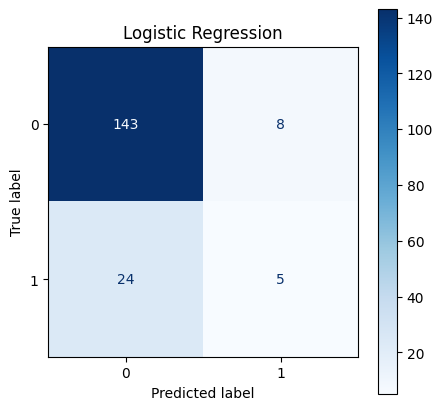

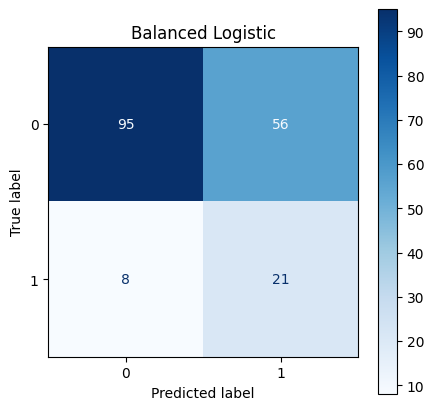

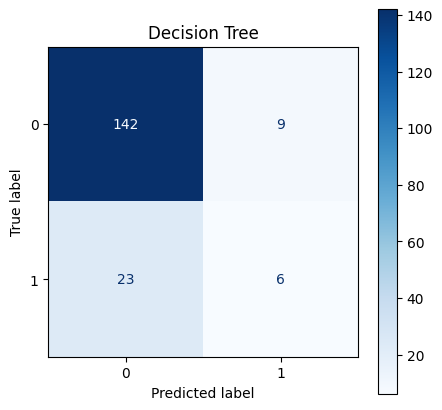

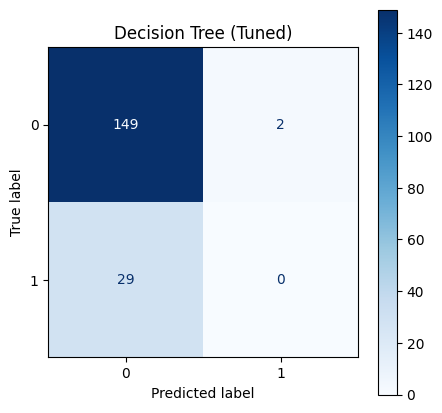

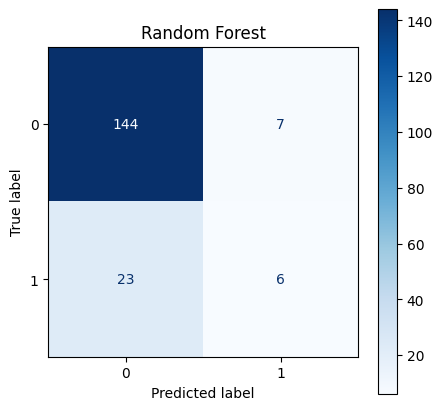

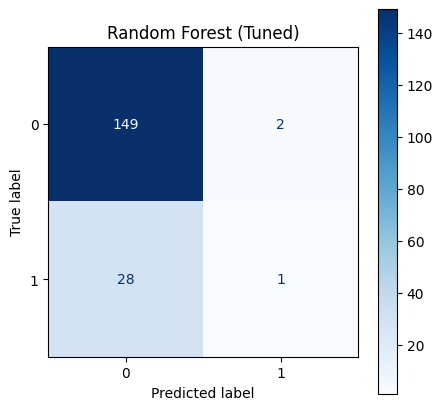

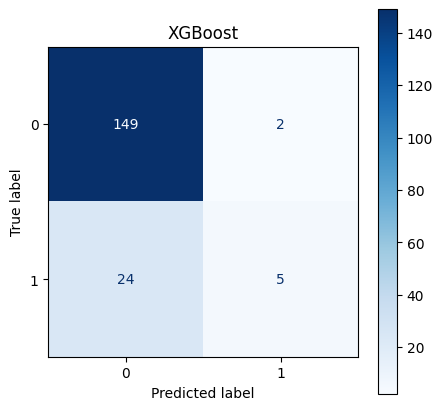

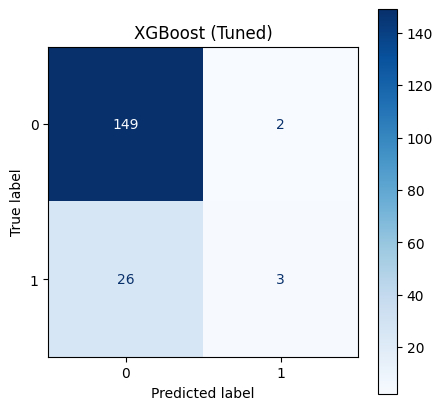

In [25]:
###############################################################
# CONFUSION MATRICES
###############################################################
# Plot Confusion Matrix for Every Model

from sklearn.metrics import ConfusionMatrixDisplay

import matplotlib.pyplot as plt

for name, model in trained_models.items():

    fig, ax = plt.subplots(figsize=(5,5))

    ConfusionMatrixDisplay.from_estimator(

        model,

        X_test,

        y_test,

        cmap="Blues",

        ax=ax

    )

    plt.title(name)

    plt.show()

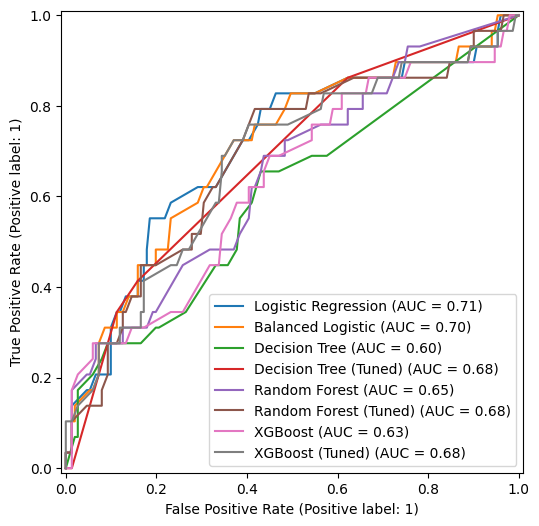

In [26]:
###############################################################
# ROC CURVES
###############################################################

from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(8,6))

for name, model in trained_models.items():

    RocCurveDisplay.from_estimator(

        model,

        X_test,

        y_test,

        name=name,

        ax=plt.gca()

    )

plt.show()

In [27]:
###############################################################
# FEATURE IMPORTANCE
###############################################################

importance_models = {

    "Balanced Logistic":trained_models["Balanced Logistic"],

    "Decision Tree":trained_models["Decision Tree"],

    "Decision Tree (Tuned)":trained_models["Decision Tree (Tuned)"],

    "Random Forest":trained_models["Random Forest"],

    "Random Forest (Tuned)":trained_models["Random Forest (Tuned)"],

    "XGBoost":trained_models["XGBoost"],

    "XGBoost (Tuned)":trained_models["XGBoost (Tuned)"]

}

feature_importance_dataframes = {}

for name, model in importance_models.items():

    if hasattr(model, "coef_"):

        importance = np.abs(model.coef_[0])

    else:

        importance = model.feature_importances_

    importance_df = pd.DataFrame({

        "Feature":X.columns,

        "Importance":importance

    }).sort_values(

        "Importance",

        ascending=False

    )

    feature_importance_dataframes[name] = importance_df # Store the DataFrame

    print("\n", "="*70)

    print(name)

    display(importance_df.head(15))


Balanced Logistic


,Feature,Importance
13,Question Intent_Understand capability / termin...,2.585118
16,Business Capability_Cloud migration and modern...,1.356124
21,Business Capability_IT operations and observab...,1.282489
12,Question Intent_Request presales guidance,1.069097
15,Business Capability_Cloud foundation and workl...,0.980422
9,Question Intent_Determine timing / applicability,0.950761
14,Business Capability_Business continuity and re...,0.909993
11,Question Intent_Evaluate options / fit,0.872021
2,Question Type_Governance / Security,0.693887
0,Question Type_Best Practice,0.574947



Decision Tree


,Feature,Importance
13,Question Intent_Understand capability / termin...,0.385674
1,Question Type_Commercial / Pricing,0.078601
2,Question Type_Governance / Security,0.071968
0,Question Type_Best Practice,0.064287
21,Business Capability_IT operations and observab...,0.049841
15,Business Capability_Cloud foundation and workl...,0.046701
12,Question Intent_Request presales guidance,0.044237
7,Question Complexity_Medium,0.044133
18,Business Capability_Enterprise data and analytics,0.034048
22,"Business Capability_Risk, compliance and ident...",0.032980



Decision Tree (Tuned)


...

,Feature,Importance
13,Question Intent_Understand capability / termin...,0.384686
8,Question Intent_Determine implementation approach,0.126801
21,Business Capability_IT operations and observab...,0.057567
12,Question Intent_Request presales guidance,0.054552
15,Business Capability_Cloud foundation and workl...,0.043001
4,Question Type_Informational,0.037420
0,Question Type_Best Practice,0.028223
1,Question Type_Commercial / Pricing,0.027799
17,Business Capability_Digital platform delivery,0.022304
2,Question Type_Governance / Security,0.021612



XGBoost


,Feature,Importance
13,Question Intent_Understand capability / termin...,0.306793
12,Question Intent_Request presales guidance,0.070991
0,Question Type_Best Practice,0.061258
10,Question Intent_Estimate commercial impact,0.060333
16,Business Capability_Cloud migration and modern...,0.054523
15,Business Capability_Cloud foundation and workl...,0.050295
6,Question Complexity_Low,0.041932
14,Business Capability_Business continuity and re...,0.040871
4,Question Type_Informational,0.039673
3,Question Type_Implementation,0.031827



XGBoost (Tuned)


,Feature,Importance
13,Question Intent_Understand capability / termin...,0.485482
12,Question Intent_Request presales guidance,0.092765
6,Question Complexity_Low,0.041386
15,Business Capability_Cloud foundation and workl...,0.040525
0,Question Type_Best Practice,0.034462
3,Question Type_Implementation,0.031852
11,Question Intent_Evaluate options / fit,0.031319
16,Business Capability_Cloud migration and modern...,0.025507
18,Business Capability_Enterprise data and analytics,0.025260
14,Business Capability_Business continuity and re...,0.023892


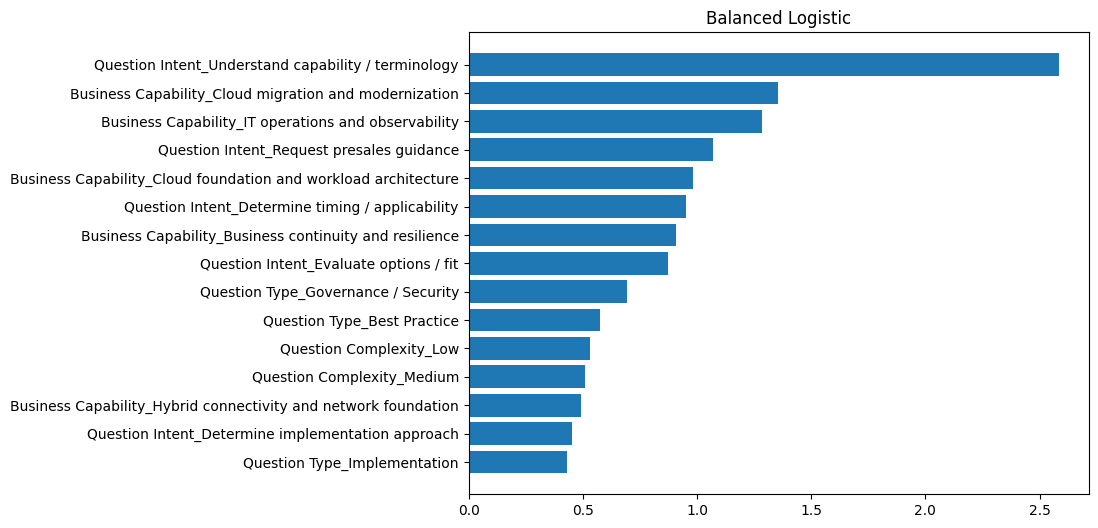

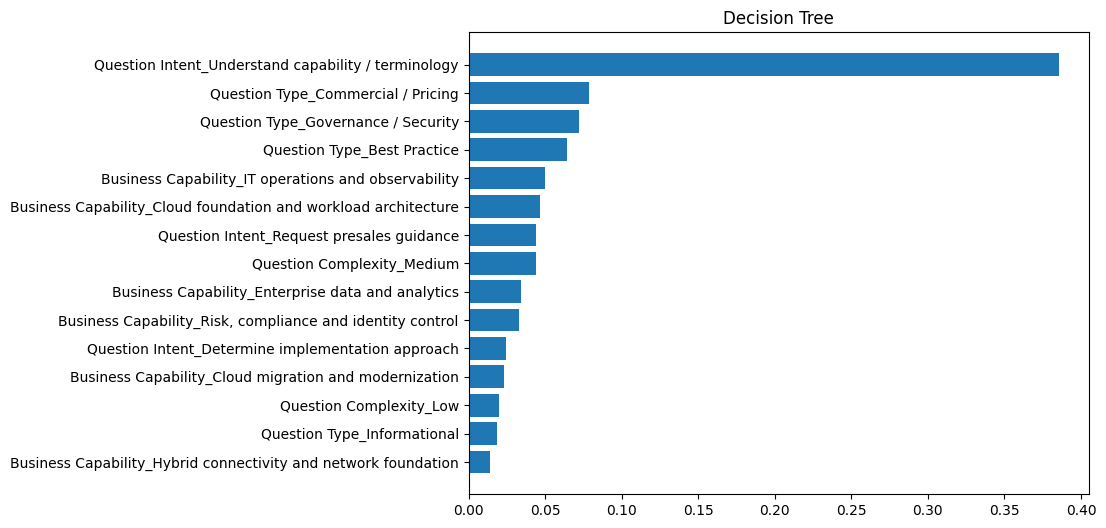

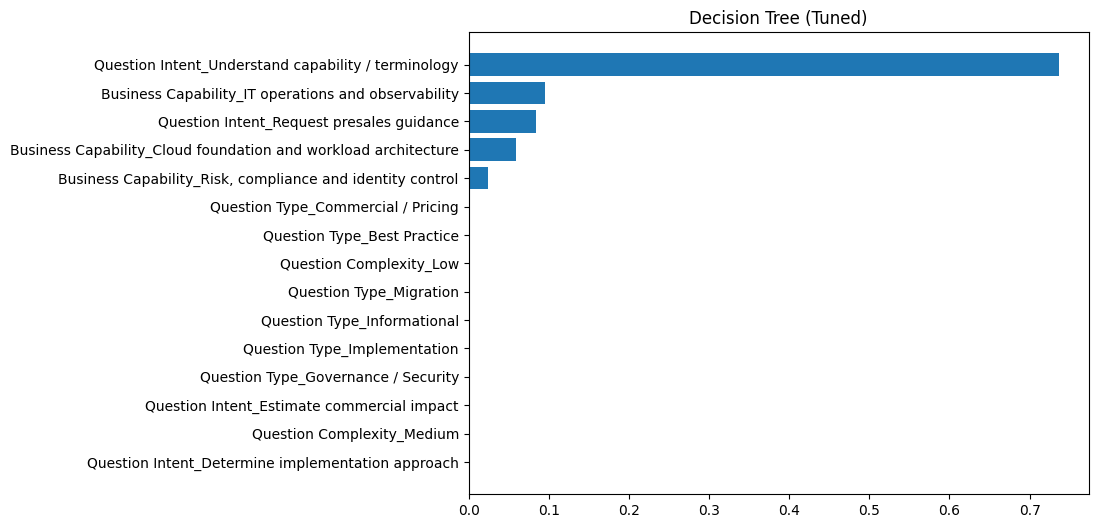

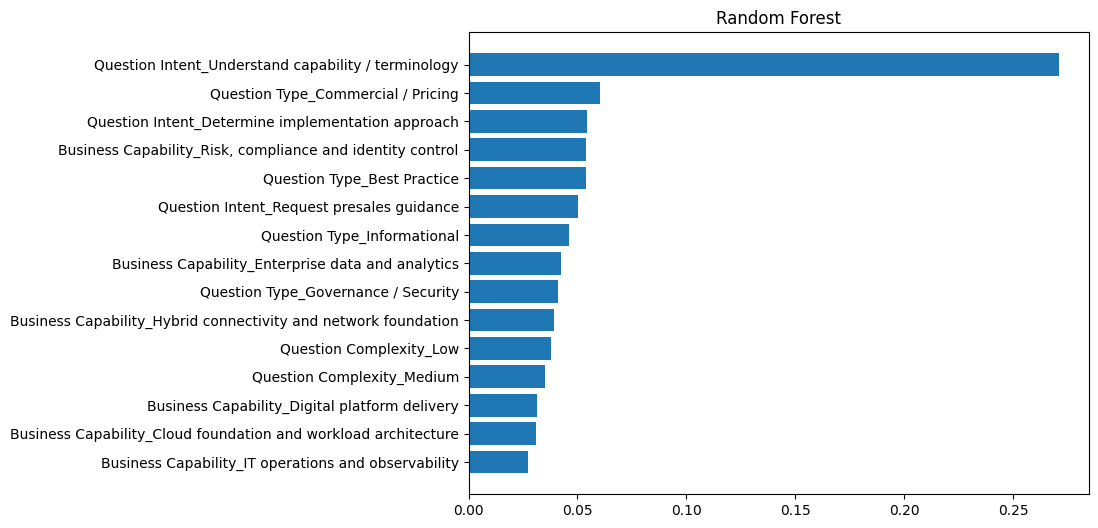

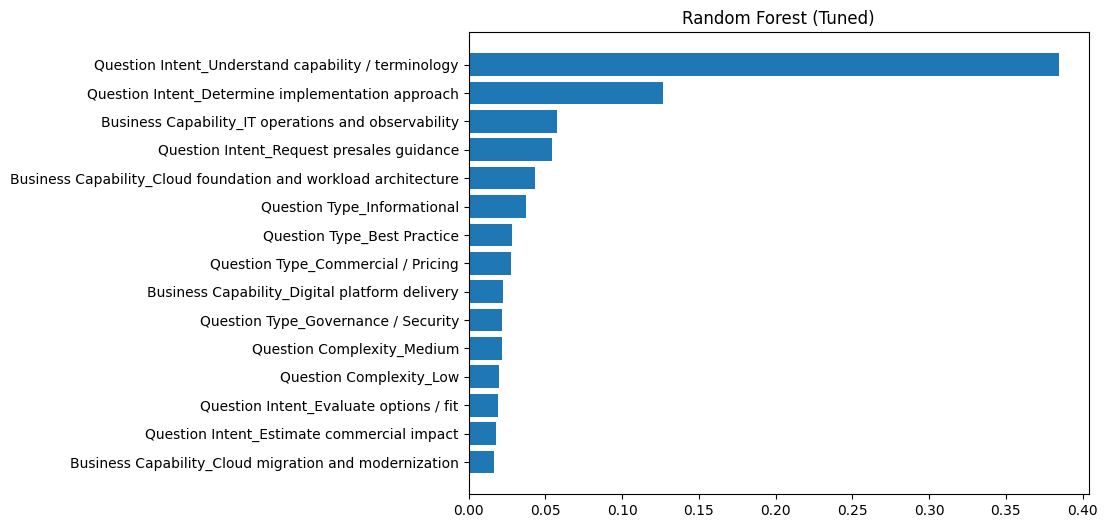

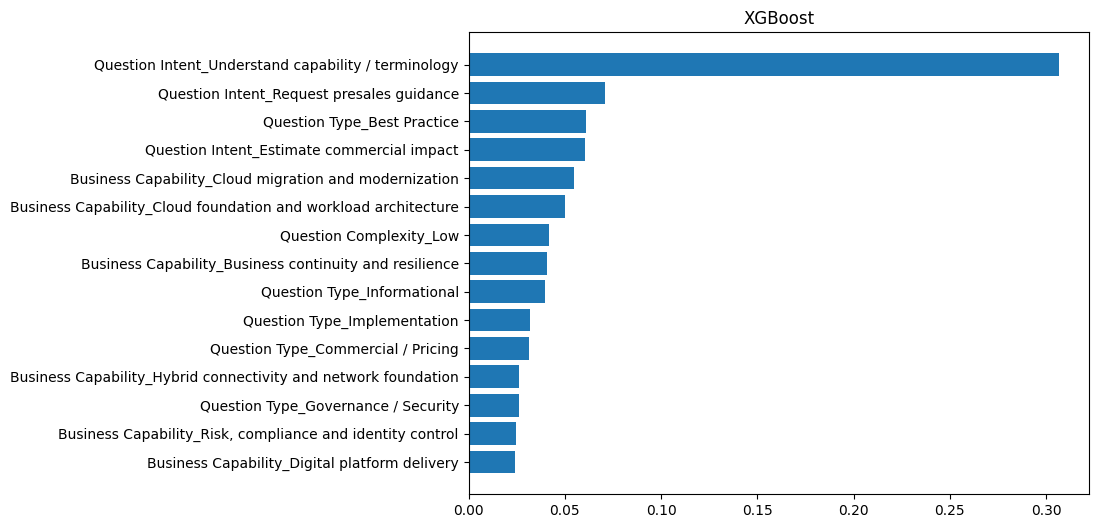

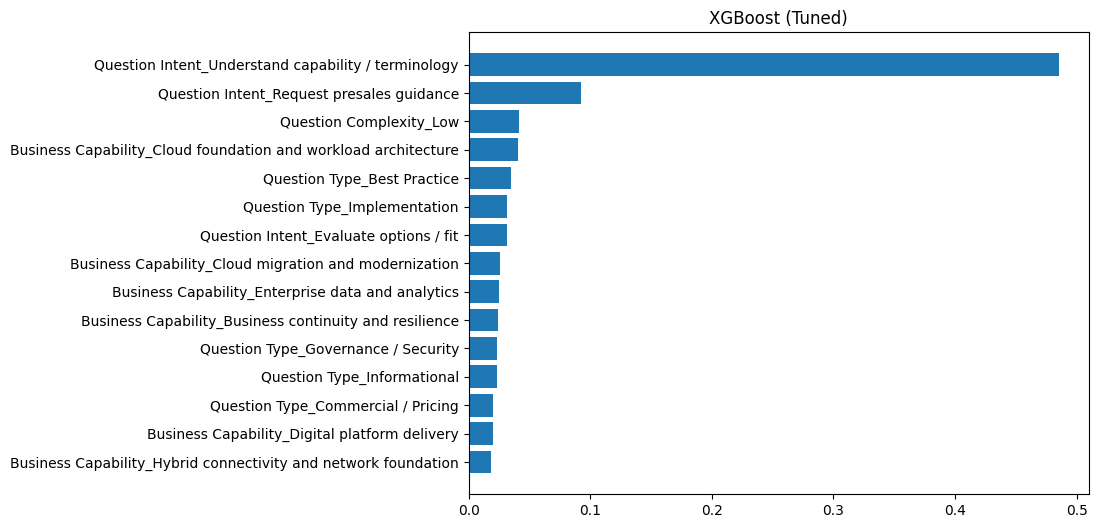

In [28]:
###############################################################
# FEATURE IMPORTANCE PLOTS
###############################################################

# Iterate over the stored feature importance DataFrames
for model_name, df_plot in feature_importance_dataframes.items():

    df_plot = df_plot.sort_values(

        by="Importance",

        ascending=False

    ).head(15)

    plt.figure(figsize=(8,6))

    plt.barh(

        df_plot["Feature"],

        df_plot["Importance"]

    )

    plt.gca().invert_yaxis()

    plt.title(model_name)

    plt.show()

In [29]:
###############################################################
# DEFAULT vs TUNED MODEL COMPARISON
###############################################################

comparison = pd.DataFrame({

    "Algorithm":[
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],

    "Default Accuracy":[
        results_df.loc[results_df.Model=="Decision Tree","Accuracy"].values[0],
        results_df.loc[results_df.Model=="Random Forest","Accuracy"].values[0],
        results_df.loc[results_df.Model=="XGBoost","Accuracy"].values[0]
    ],

    "Tuned Accuracy":[
        results_df.loc[results_df.Model=="Decision Tree (Tuned)","Accuracy"].values[0],
        results_df.loc[results_df.Model=="Random Forest (Tuned)","Accuracy"].values[0],
        results_df.loc[results_df.Model=="XGBoost (Tuned)","Accuracy"].values[0]
    ],

    "Default F1":[
        results_df.loc[results_df.Model=="Decision Tree","F1"].values[0],
        results_df.loc[results_df.Model=="Random Forest","F1"].values[0],
        results_df.loc[results_df.Model=="XGBoost","F1"].values[0]
    ],

    "Tuned F1":[
        results_df.loc[results_df.Model=="Decision Tree (Tuned)","F1"].values[0],
        results_df.loc[results_df.Model=="Random Forest (Tuned)","F1"].values[0],
        results_df.loc[results_df.Model=="XGBoost (Tuned)","F1"].values[0]
    ],

    "Default ROC-AUC":[
        results_df.loc[results_df.Model=="Decision Tree","ROC_AUC"].values[0],
        results_df.loc[results_df.Model=="Random Forest","ROC_AUC"].values[0],
        results_df.loc[results_df.Model=="XGBoost","ROC_AUC"].values[0]
    ],

    "Tuned ROC-AUC":[
        results_df.loc[results_df.Model=="Decision Tree (Tuned)","ROC_AUC"].values[0],
        results_df.loc[results_df.Model=="Random Forest (Tuned)","ROC_AUC"].values[0],
        results_df.loc[results_df.Model=="XGBoost (Tuned)","ROC_AUC"].values[0]
    ]

})

comparison["Accuracy Improvement"] = \
comparison["Tuned Accuracy"]-comparison["Default Accuracy"]

comparison["F1 Improvement"] = \
comparison["Tuned F1"]-comparison["Default F1"]

comparison["ROC Improvement"] = \
comparison["Tuned ROC-AUC"]-comparison["Default ROC-AUC"]

display(comparison.round(3))

,Algorithm,Default Accuracy,Tuned Accuracy,Default F1,Tuned F1,Default ROC-AUC,Tuned ROC-AUC,Accuracy Improvement,F1 Improvement,ROC Improvement
0,Decision Tree,0.822,0.828,0.273,0.000,0.601,0.682,0.006,-0.273,0.081
1,Random Forest,0.833,0.833,0.286,0.062,0.648,0.684,0.000,-0.223,0.036
2,XGBoost,0.856,0.844,0.278,0.176,0.633,0.676,-0.011,-0.101,0.043


In [100]:
###############################################################
# SAVE HYPERPARAMETER TUNING COMPARISON TO EXCEL
###############################################################

comparison_df.to_excel(
    "/content/drive/MyDrive/DataAnalytics_Capstone/Hyperparameter_Tuning_Comparison.xlsx",
    index=False
)

print("Hyperparameter tuning comparison saved to Excel.")

Hyperparameter tuning comparison saved to Excel.


Decision Tree Visualization


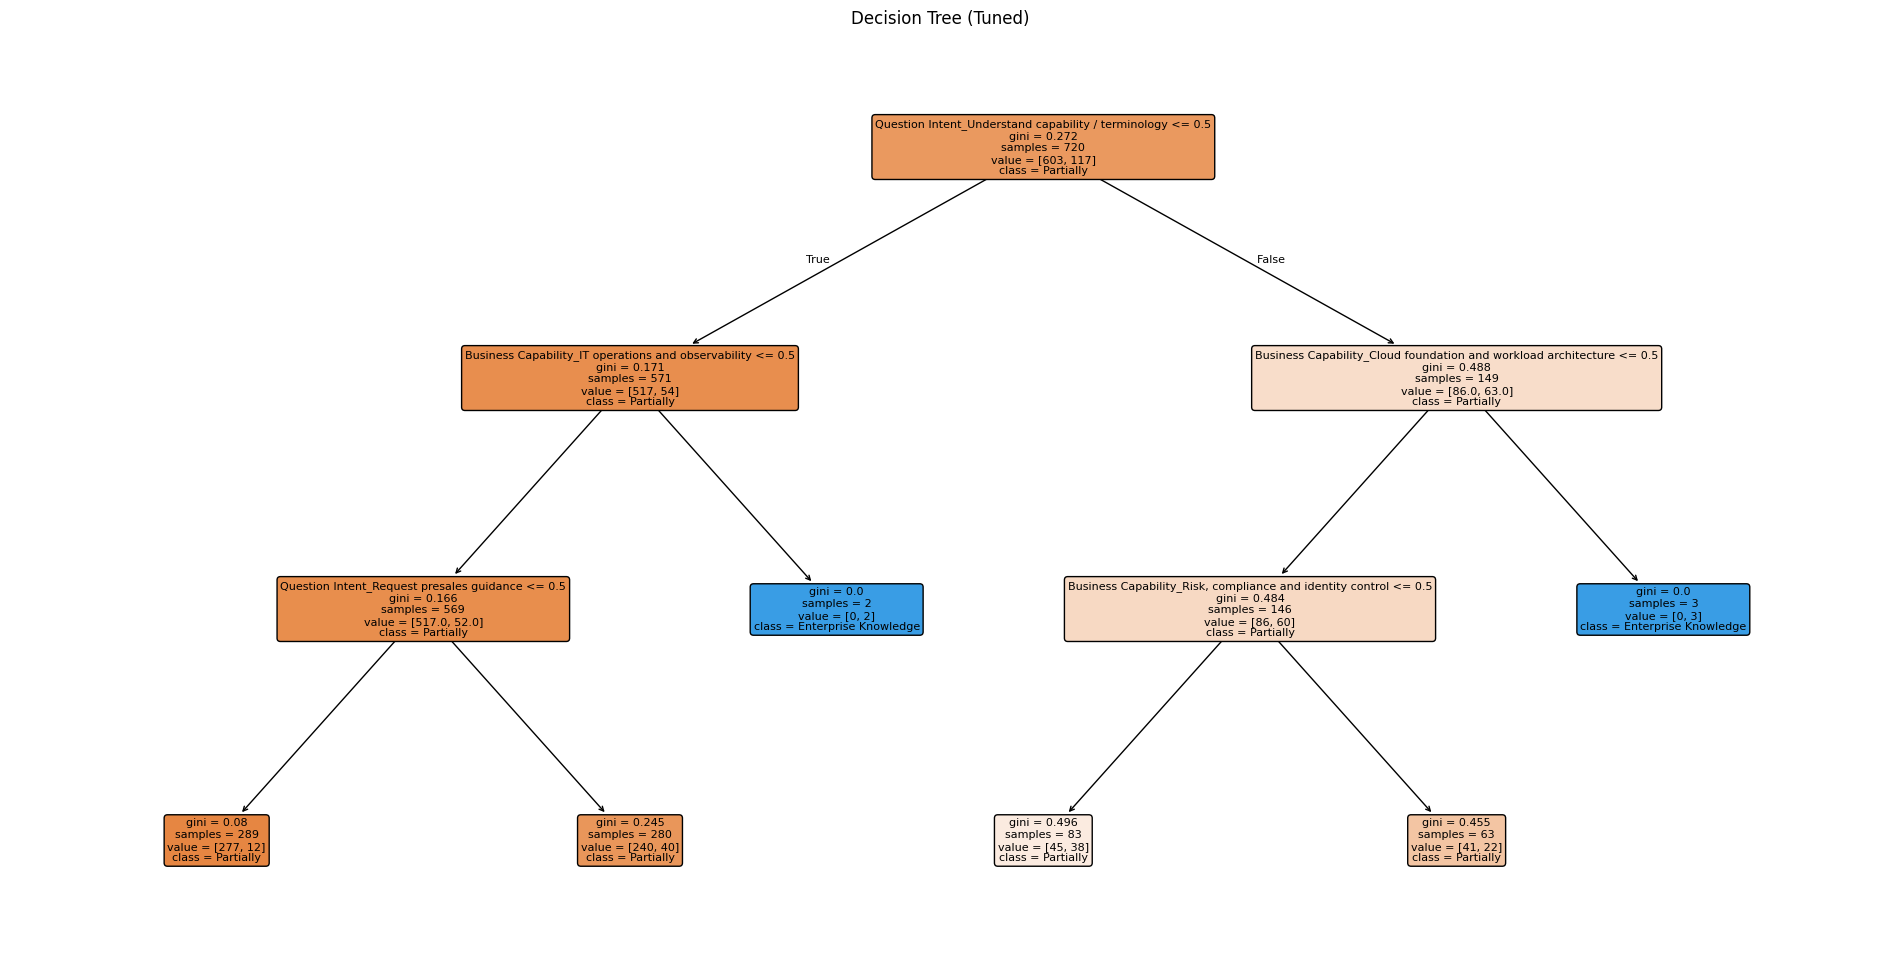

SHAP Explainability : Random Forest (Tuned)


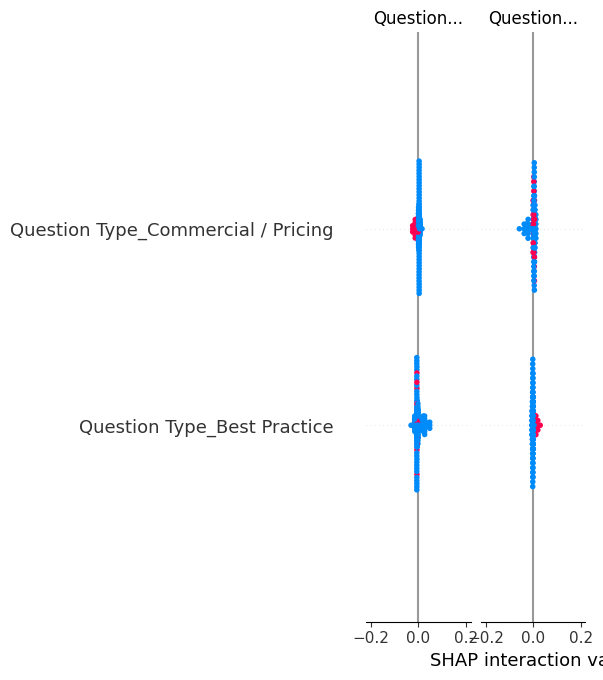

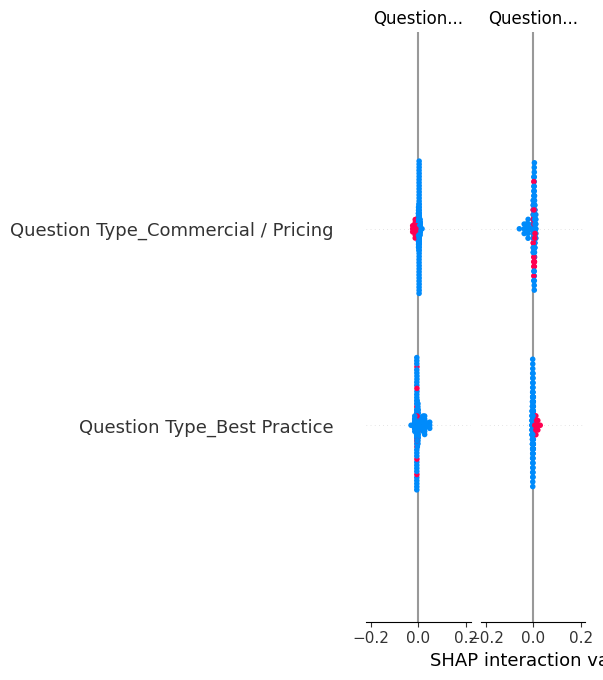

SHAP Explainability : XGBoost (Tuned)


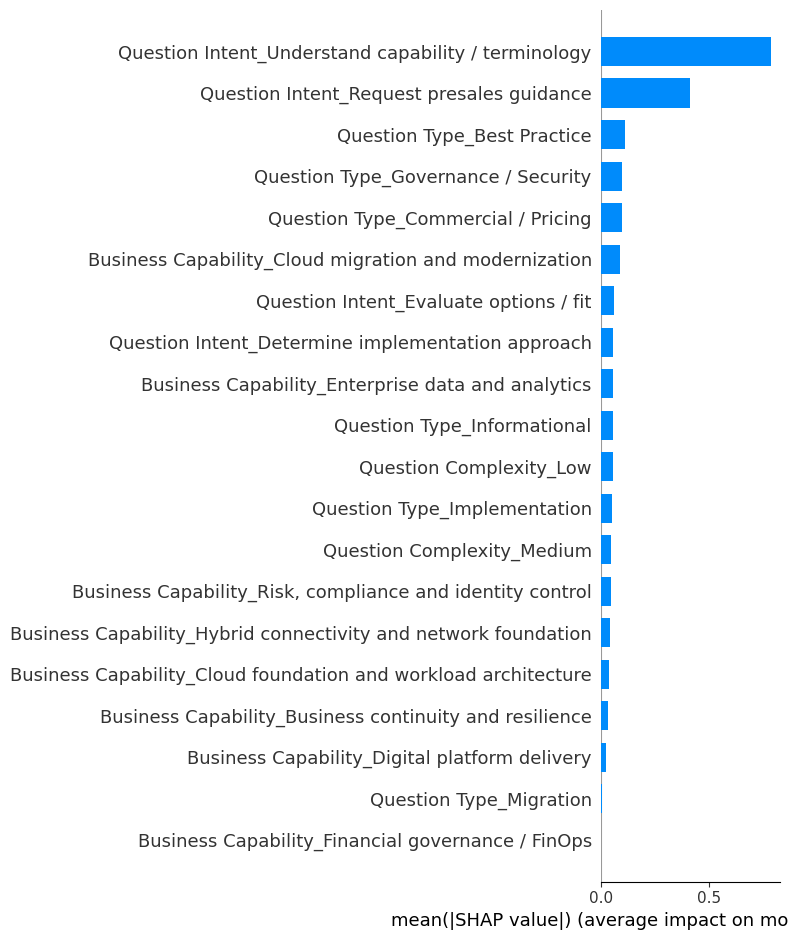

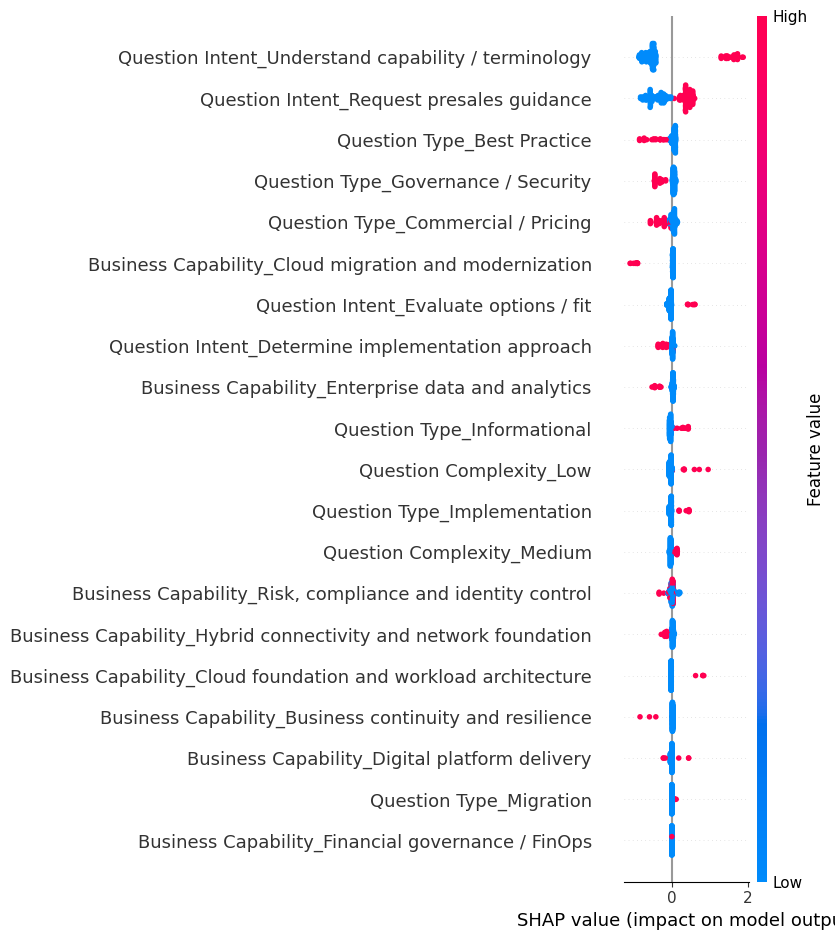

Local SHAP Explanation (First Test Sample)


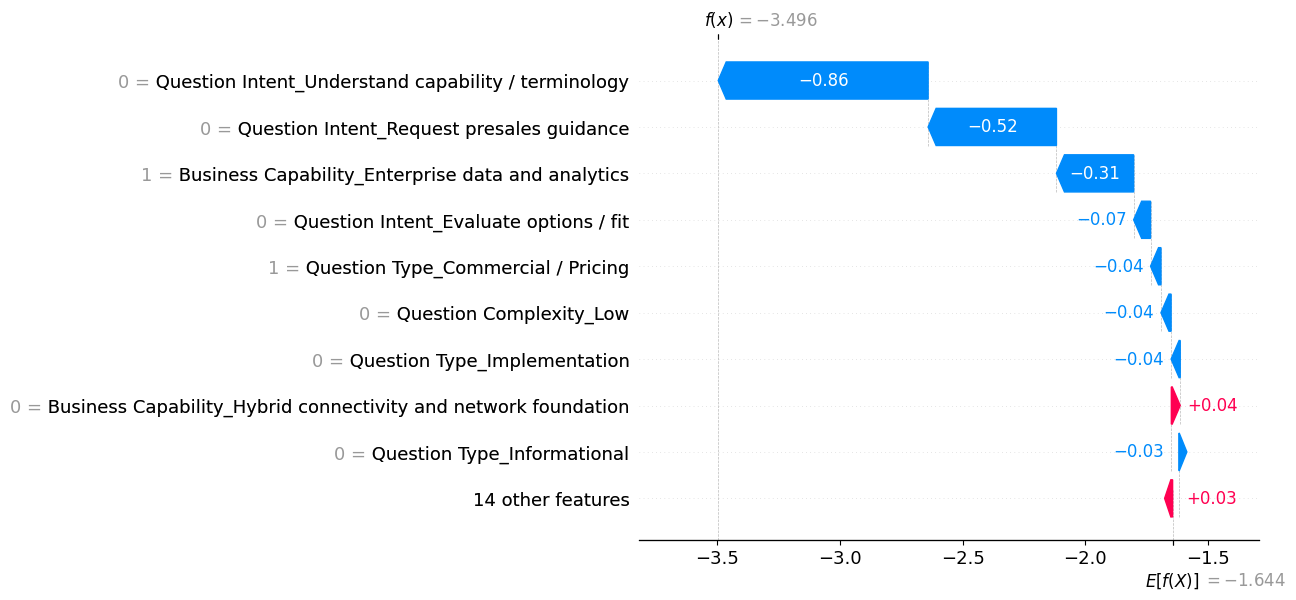

In [30]:
###############################################################
# EXPLAINABILITY
#
# 1. Decision Tree Visualization
# 2. SHAP - Random Forest (Tuned)
# 3. SHAP - XGBoost (Tuned)
###############################################################

import shap
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

###############################################################
# PART 1 : Decision Tree Visualization
###############################################################

print("="*80)
print("Decision Tree Visualization")
print("="*80)

plt.figure(figsize=(24,12))

plot_tree(

    trained_models["Decision Tree (Tuned)"],

    feature_names=X.columns,

    class_names=[
        "Partially",
        "Enterprise Knowledge"
    ],

    filled=True,

    rounded=True,

    fontsize=8

)

plt.title("Decision Tree (Tuned)")

plt.show()


###############################################################
# PART 2 : SHAP Explainability - Random Forest
###############################################################

print("="*80)
print("SHAP Explainability : Random Forest (Tuned)")
print("="*80)

rf_model = trained_models["Random Forest (Tuned)"]

rf_explainer = shap.TreeExplainer(rf_model)

rf_shap = rf_explainer.shap_values(X_test)

# Handle binary classification output
if isinstance(rf_shap, list):
    rf_shap = rf_shap[1]

# Global Feature Importance
shap.summary_plot(
    rf_shap,
    X_test,
    plot_type="bar",
    show=True
)

# Beeswarm Plot
shap.summary_plot(
    rf_shap,
    X_test,
    show=True
)


###############################################################
# PART 3 : SHAP Explainability - XGBoost
###############################################################

print("="*80)
print("SHAP Explainability : XGBoost (Tuned)")
print("="*80)

xgb_model = trained_models["XGBoost (Tuned)"]

xgb_explainer = shap.TreeExplainer(xgb_model)

xgb_shap = xgb_explainer.shap_values(X_test)

# Handle binary classification output
if isinstance(xgb_shap, list):
    xgb_shap = xgb_shap[1]

# Global Importance
shap.summary_plot(
    xgb_shap,
    X_test,
    plot_type="bar",
    show=True
)

# Beeswarm
shap.summary_plot(
    xgb_shap,
    X_test,
    show=True
)

###############################################################
# PART 4 : Local Explainability
###############################################################

print("="*80)
print("Local SHAP Explanation (First Test Sample)")
print("="*80)

shap.plots.waterfall(

    shap.Explanation(

        values=xgb_shap[0],

        base_values=xgb_explainer.expected_value,

        data=X_test.iloc[0],

        feature_names=X_test.columns

    )

)

In [31]:
###############################################################
# TOP 10 IMPORTANT FEATURES COMPARISON
###############################################################

comparison = pd.DataFrame({

    "Random Forest":

        trained_models["Random Forest (Tuned)"].feature_importances_,

    "XGBoost":

        trained_models["XGBoost (Tuned)"].feature_importances_

},

index=X.columns)

comparison["Average Importance"] = comparison.mean(axis=1)

comparison = comparison.sort_values(

    "Average Importance",

    ascending=False

)

display(comparison.head(10).round(4))

,Random Forest,XGBoost,Average Importance
Question Intent_Understand capability / terminology,0.3847,0.4855,0.4351
Question Intent_Request presales guidance,0.0546,0.0928,0.0737
Question Intent_Determine implementation approach,0.1268,0.0175,0.0722
Business Capability_Cloud foundation and workload architecture,0.0430,0.0405,0.0418
Question Type_Best Practice,0.0282,0.0345,0.0313
Question Complexity_Low,0.0196,0.0414,0.0305
Question Type_Informational,0.0374,0.0230,0.0302
Business Capability_IT operations and observability,0.0576,0.0000,0.0288
Question Intent_Evaluate options / fit,0.0190,0.0313,0.0252
Question Type_Commercial / Pricing,0.0278,0.0199,0.0238


In [101]:
results_df.to_csv(

    "/content/drive/MyDrive/DataAnalytics_Capstone/Model_Comparison.csv",

    index=False

)

print("Model comparison saved.")

# Iterate over the stored feature importance DataFrames
for model_name, importance_df in feature_importance_dataframes.items():

    importance_df.to_csv(

        model_name.replace(" ","_")+"_Importance.csv",

        index=False

    )

#Also saving hyperparameter comparisons
comparison.to_csv(
    "/content/drive/MyDrive/DataAnalytics_Capstone/Hyperparameter_Tuning_Comparison.csv",
    index=False
)

Model comparison saved.


AttributeError: 'list' object has no attribute 'to_csv'

To do:  Since the dataset is imbalanced, optimizing for accuracy pushes the models toward predicting the majority class. I would recommend change tuning objective to scoring="f1" or scoring="recall" (or f1_macro/f1_weighted depending on  chosen emphasis). This is likely to improve the tuned Random Forest and XGBoost models considerably while making the model selection more consistent with the business objective of correctly identifying questions that require enterprise knowledge.